# Создание собственного распределения в Python
Рассмотрим функцию

$$f(x) = \begin{cases} \cos x, & 0 \leq x \leq \dfrac{\pi}{2}; \\ 0, & \text{иначе.} \end{cases}$$

Покажем, что $f(x)$ - плотность вероятности некоторой непрерывной случайной величины $X$, зададим её в виде класса, унаследованного от `rv_continuous`, и исследуем. Также:
* проверим условие нормировки плотности;
* построим графики плотности и функции распределения;
* найдём вероятность попадания $X$ в интервал;
* вычислим $M(X)$, $D(X)$, $\sigma(X)$;
* найдём квантиль уровня $q$ и $p\%$-ную точку;
* определим коэффициент асимметрии и эксцесс.

## Теоретическая часть
---
Функция распределения $F(x) = \displaystyle\int_{-\infty}^{x} f(t)\,dt$:

$$F(x) = \begin{cases} 0, & x < 0; \\ \sin x, & 0 \leq x \leq \dfrac{\pi}{2}; \\ 1, & x > \dfrac{\pi}{2}. \end{cases}$$

* Квантиль уровня $q$ - решение уравнения $F(x_q) = q$, то есть $x_q = \arcsin q$.
* $p\%$-ная точка $x_{p\%}$ определяется условием $P(X \geq x_{p\%}) = \dfrac{p}{100}$, то есть это квантиль уровня $1 - \dfrac{p}{100}$.
* Числовые характеристики:<br>
$M(X) = \displaystyle\int_0^{\pi/2} x \cos x\,dx = \frac{\pi}{2} - 1$, $ D(X) = M(X^2) - M^2(X) = \frac{\pi^2}{4} - 2 - \left(\frac{\pi}{2} - 1\right)^2 = \pi - 3$
* Коэффициент асимметрии $A = \dfrac{\mu_3}{\sigma^3}$ и эксцесс $E = \dfrac{\mu_4}{\sigma^4} - 3$, где $\mu_k = M\left[(X - M(X))^k\right]$ - центральные моменты.<br>
Интегрированием по частям получаем $\mu_3 = 3\pi - \dfrac{3\pi^2}{4} - 2$, $\mu_4 = \dfrac{\pi^3}{2} - 3\pi^2 - 6\pi + 33$.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import rv_continuous, skew, kurtosis
from scipy import integrate

np.set_printoptions(formatter={'float_kind': '{:0.4f}'.format})
%matplotlib inline

## Класс собственного распределения
---
В классе, унаследованном от `rv_continuous`, задаём плотность `_pdf`, функцию распределения `_cdf` и квантильную функцию `_ppf`. Границы носителя $[a, b]$ передаются при создании экземпляра: вне этого отрезка `scipy` сам возвращает $0$ для плотности и $0$ или $1$ для функции распределения.

In [17]:
class CosDistribution(rv_continuous):
    def _pdf(self, x):
        """Плотность распределения"""
        return np.cos(x)

    def _cdf(self, x):
        """Функция распределения"""
        return np.sin(x)

    def _ppf(self, q):
        """Обратная функция распределения (квантильная функция)"""
        return np.arcsin(q)


a, b = 0.0, np.pi / 2
custom_dist = CosDistribution(a=a, b=b, name='cos_dist')

sample = custom_dist.rvs(size=10000, random_state=42)

print(f"Размер выборки: {len(sample)}")
print(f"Первые 10 значений: {sample[:10]}")

Размер выборки: 10000
Первые 10 значений: [0.3839 1.2555 0.8212 0.6418 0.1567 0.1566 0.0581 1.0475 0.6449 0.7868]


## 1. Условие нормировки
---
Функция $f(x)$ является плотностью, если $f(x) \geq 0$ и $\displaystyle\int_{-\infty}^{+\infty} f(x)\,dx = 1$. Неотрицательность очевидна ($\cos x \geq 0$ при $x \in \left[0, \frac{\pi}{2}\right]$), интеграл проверим численно.

In [18]:
x_grid = np.linspace(a, b, 1000)
print(f"Наименьшее значение плотности на [a, b]: {custom_dist.pdf(x_grid).min():.4f}")

print("\nПроверка нормировки плотности:")
integral, error = integrate.quad(custom_dist.pdf, a, b)
print(f"∫f(x)dx на [{a}, π/2] = {integral:.4f} (ошибка: {error:.2e})")

print("\nПроверка в граничных точках:")
print(f"F({a}) = {custom_dist.cdf(a):.4f}")
print(f"F(π/2) = {custom_dist.cdf(b):.4f}")

print("\nПроверка связи F(x) = ∫f(t)dt при x = 1:")
print(f"∫f(t)dt на [{a}, 1] = {integrate.quad(custom_dist.pdf, a, 1)[0]:.6f}, F(1) = {custom_dist.cdf(1):.6f}")

Наименьшее значение плотности на [a, b]: 0.0000

Проверка нормировки плотности:
∫f(x)dx на [0.0, π/2] = 1.0000 (ошибка: 1.11e-14)

Проверка в граничных точках:
F(0.0) = 0.0000
F(π/2) = 1.0000

Проверка связи F(x) = ∫f(t)dt при x = 1:
∫f(t)dt на [0.0, 1] = 0.841471, F(1) = 0.841471


## 2. Графики плотности и функции распределения

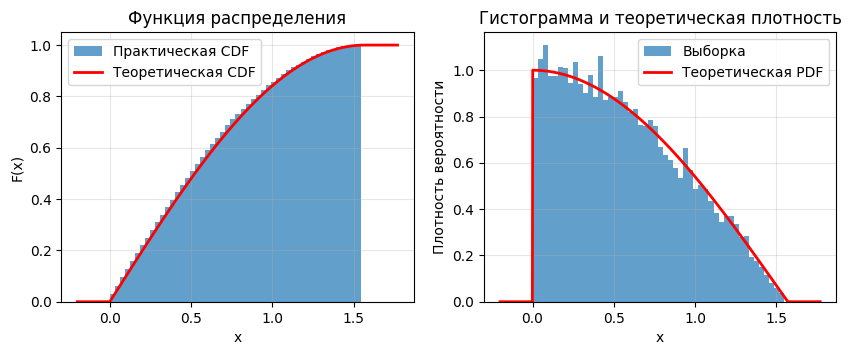

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
x_plot = np.linspace(a - 0.2, b + 0.2, 1000)

# 1. Функция распределения
ax1.hist(sample, bins=50, density=True, cumulative=True,
         alpha=0.7, label='Практическая CDF')
ax1.plot(x_plot, custom_dist.cdf(x_plot), 'r-', linewidth=2,
         label='Теоретическая CDF')
ax1.set_xlabel('x')
ax1.set_ylabel('F(x)')
ax1.set_title('Функция распределения')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# 2. Гистограмма и теоретическая плотность
ax2.hist(sample, bins=50, density=True, alpha=0.7, label='Выборка')
ax2.plot(x_plot, custom_dist.pdf(x_plot), 'r-', linewidth=2,
         label='Теоретическая PDF')
ax2.set_xlabel('x')
ax2.set_ylabel('Плотность вероятности')
ax2.set_title('Гистограмма и теоретическая плотность')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.show()

## 3. Вероятность попадания в интервал
---
$$P(\alpha < X < \beta) = F(\beta) - F(\alpha) = \int_{\alpha}^{\beta} f(x)\,dx.$$

Найдём вероятность попадания $X$ в интервал $(0.5;\ 1.2)$ четырьмя способами.

In [20]:
alpha, beta = 0.5, 1.2

P_theory = np.sin(beta) - np.sin(alpha)
P_cdf = custom_dist.cdf(beta) - custom_dist.cdf(alpha)
P_int = integrate.quad(custom_dist.pdf, alpha, beta)[0]
P_exp = np.mean((sample > alpha) & (sample < beta))

print(f"По формуле sin(β) - sin(α): {P_theory:.4f}")
print(f"Через функцию распределения: {P_cdf:.4f}")
print(f"Через интеграл от плотности: {P_int:.4f}")
print(f"Доля точек выборки в интервале: {P_exp:.4f}")
print(f"Абсолютная ошибка (выборка и теория): {abs(P_exp - P_theory):.4f}")

По формуле sin(β) - sin(α): 0.4526
Через функцию распределения: 0.4526
Через интеграл от плотности: 0.4526
Доля точек выборки в интервале: 0.4458
Абсолютная ошибка (выборка и теория): 0.0068


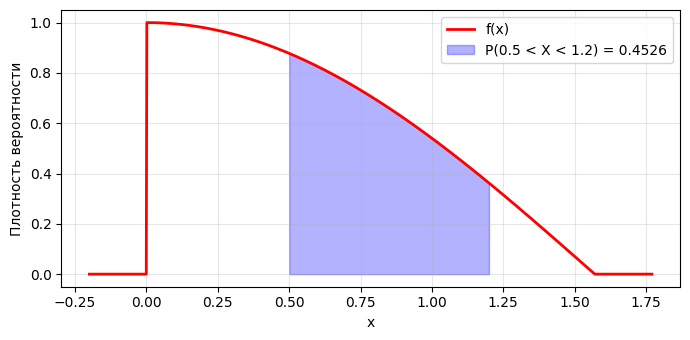

In [21]:
plt.figure(figsize=(7, 3.5))
plt.plot(x_plot, custom_dist.pdf(x_plot), color='RED', linewidth=2, label='f(x)')
x_fill = np.linspace(alpha, beta, 200)
plt.fill_between(x_fill, custom_dist.pdf(x_fill), color='BLUE', alpha=0.3,
                 label=f'P({alpha} < X < {beta}) = {P_cdf:.4f}')
plt.xlabel('x')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Математическое ожидание, дисперсия и среднее квадратическое отклонение
---

In [22]:
M = custom_dist.mean()
D = custom_dist.var()
S = custom_dist.std()

M_int = integrate.quad(lambda x: x * custom_dist.pdf(x), a, b)[0]
D_int = integrate.quad(lambda x: x ** 2 * custom_dist.pdf(x), a, b)[0] - M_int ** 2

print(f"Математическое ожидание: M(X) = {M:.4f}  (по определению: {M_int:.4f}, теория π/2 - 1 = {np.pi / 2 - 1:.4f})")
print(f"Дисперсия: D(X) = {D:.4f}  (по определению: {D_int:.4f}, теория π - 3 = {np.pi - 3:.4f})")
print(f"Среднее квадратическое отклонение: σ(X) = {S:.4f}  (теория √(π - 3) = {np.sqrt(np.pi - 3):.4f})")

print(f"\nПо выборке: среднее = {sample.mean():.4f}, дисперсия = {sample.var():.4f}, σ = {sample.std():.4f}")

Математическое ожидание: M(X) = 0.5708  (по определению: 0.5708, теория π/2 - 1 = 0.5708)
Дисперсия: D(X) = 0.1416  (по определению: 0.1416, теория π - 3 = 0.1416)
Среднее квадратическое отклонение: σ(X) = 0.3763  (теория √(π - 3) = 0.3763)

По выборке: среднее = 0.5628, дисперсия = 0.1396, σ = 0.3736


## 5. Квантиль уровня $q$ и $p\%$-ная точка
---
Возьмём $q = 0.9$ и $p = 5$. Квантиль $x_{0.9}$ отсекает слева площадь $0.9$, а $5\%$-ная точка $x_{5\%}$ - квантиль уровня $0.95$ - отсекает справа площадь $0.05$.

In [23]:
q, p = 0.9, 5

x_q = custom_dist.ppf(q)
x_p = custom_dist.ppf(1 - p / 100)

print(f"Квантиль уровня {q}: x_q = {x_q:.4f}  (теория arcsin({q}) = {np.arcsin(q):.4f})")
print(f"Проверка: F(x_q) = {custom_dist.cdf(x_q):.4f}")
print(f"\n{p}%-ная точка: x_p = {x_p:.4f}  (теория arcsin({1 - p / 100}) = {np.arcsin(1 - p / 100):.4f})")
print(f"Проверка: P(X >= x_p) = {custom_dist.sf(x_p):.4f}")
print(f"\nМедиана (квантиль уровня 0.5): Me(X) = {custom_dist.median():.4f}  (теория π/6 = {np.pi / 6:.4f})")

Квантиль уровня 0.9: x_q = 1.1198  (теория arcsin(0.9) = 1.1198)
Проверка: F(x_q) = 0.9000

5%-ная точка: x_p = 1.2532  (теория arcsin(0.95) = 1.2532)
Проверка: P(X >= x_p) = 0.0500

Медиана (квантиль уровня 0.5): Me(X) = 0.5236  (теория π/6 = 0.5236)


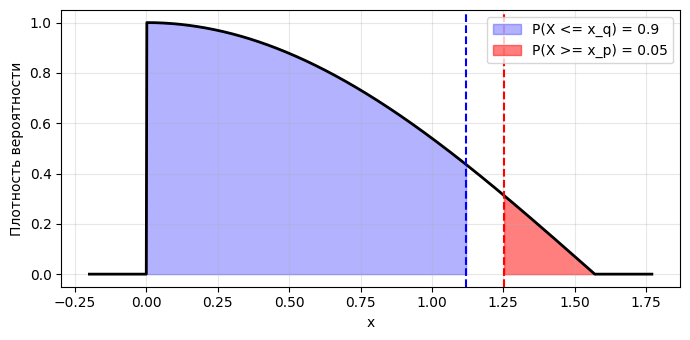

In [24]:
plt.figure(figsize=(7, 3.5))
plt.plot(x_plot, custom_dist.pdf(x_plot), color='BLACK', linewidth=2)

x_left = np.linspace(a, x_q, 200)
x_right = np.linspace(x_p, b, 100)
plt.fill_between(x_left, custom_dist.pdf(x_left), color='BLUE', alpha=0.3, label=f'P(X <= x_q) = {q}')
plt.fill_between(x_right, custom_dist.pdf(x_right), color='RED', alpha=0.5, label=f'P(X >= x_p) = {p / 100}')
plt.axvline(x_q, color='BLUE', linestyle='--')
plt.axvline(x_p, color='RED', linestyle='--')

plt.xlabel('x')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Коэффициент асимметрии и эксцесс
---
Центральные моменты $\mu_3$ и $\mu_4$ вычислим интегрированием плотности, затем найдём $A = \dfrac{\mu_3}{\sigma^3}$ и $E = \dfrac{\mu_4}{\sigma^4} - 3$ и сравним со значениями, которые возвращают `scipy` (метод `stats`) и выборочные оценки.

In [25]:
def central_moment(k):
    return integrate.quad(lambda x: (x - M) ** k * custom_dist.pdf(x), a, b)[0]

A = central_moment(3) / S ** 3
E = central_moment(4) / S ** 4 - 3

mu3 = 3 * np.pi - 3 * np.pi ** 2 / 4 - 2
mu4 = np.pi ** 3 / 2 - 3 * np.pi ** 2 - 6 * np.pi + 33
A_theory = mu3 / (np.pi - 3) ** 1.5
E_theory = mu4 / (np.pi - 3) ** 2 - 3

A_scipy, E_scipy = custom_dist.stats(moments='sk')

print(f"Коэффициент асимметрии: A = {A:.4f}  (scipy: {A_scipy:.4f}, теория: {A_theory:.4f}, выборка: {skew(sample):.4f})")
print(f"Эксцесс: E = {E:.4f}  (scipy: {E_scipy:.4f}, теория: {E_theory:.4f}, выборка: {kurtosis(sample):.4f})")

Коэффициент асимметрии: A = 0.4237  (scipy: 0.4237, теория: 0.4237, выборка: 0.4452)
Эксцесс: E = -0.7670  (scipy: -0.7670, теория: -0.7670, выборка: -0.7422)


## Вывод
---
* Условие нормировки выполнено: $\displaystyle\int_0^{\pi/2} \cos x\,dx = 1$, а значит, $f(x)$ - плотность вероятности непрерывной случайной величины; численные результаты, полученные в `scipy`, совпадают с теоретическими формулами.
* Математическое ожидание $M(X) = \frac{\pi}{2} - 1 \approx 0.5708$ больше медианы $Me(X) = \frac{\pi}{6} \approx 0.5236$, а мода $Mo(X) = 0$ (максимум плотности в левой границе носителя). Это согласуется с положительной асимметрией $A \approx 0.4237$: у распределения более длинный правый хвост.
* Эксцесс $E \approx -0.7670 < 0$, значит, распределение имеет более плоскую вершину, чем нормальное.